# P3 실습: 합성곱 신경망과 컴퓨터 비전

이미지의 높이와 너비를 하나의 벡터로 펼치는 다층 퍼셉트론(MLP)과 달리, **합성곱 신경망**(CNN)은 **이미지의 공간 구조를 유지하면서** 학습한다.

**실습의 흐름**

1. MNIST를 CNN으로 분류하고 합성곱·풀링·특성맵을 관찰한다.
2. Keras와 PyTorch로 동일한 CNN 개념을 표현한다.
3. 작은 이미지 데이터셋에서 데이터 증식과 전이 학습을 비교한다.
4. 이미지 분류를 넘어 객체 탐지 문제를 살펴본다.
5. 잔차 연결, 배치 정규화, 채널 분리 합성곱을 간단한 코드로 확인한다.

**핵심 질문:** 코드가 실행되는가보다 **입력·타깃·모델·평가 방법이 문제에 적합한가**를 판단한다.

**실행 준비**

Keras는 TensorFlow 백엔드를 기준으로 한다. 한 번에 위에서 아래로 실행한다. 공개 데이터셋과 사전훈련 가중치를 처음 불러올 때는 인터넷 연결이 필요하다. GPU가 없다면 각 모델의 에포크 수 또는 샘플 수를 줄여도 된다.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

keras.utils.set_random_seed(42)
print("Keras:", keras.__version__)

Keras: 3.13.2


## MNIST: 이미지를 펼치지 않고 분류하기

### 입력 구조 확인

MLP는 `(28, 28)` 이미지를 `784`개의 값으로 펼쳐 입력할 수 있다. CNN은 높이와 너비, 채널의 구분을 유지한다. 흑백 이미지에는 채널이 1개 있다.

In [2]:
from keras.datasets import mnist

(mnist_x_all, mnist_y_all), (mnist_x_test, mnist_y_test) = mnist.load_data()

mnist_x_all = mnist_x_all.astype("float32")[..., None] / 255.0
mnist_x_test = mnist_x_test.astype("float32")[..., None] / 255.0

rng = np.random.default_rng(42)
order = rng.permutation(len(mnist_x_all))
n_val = int(len(mnist_x_all) * 0.10)
train_ids, val_ids = order[:-n_val], order[-n_val:]

mnist_x_train, mnist_y_train = mnist_x_all[train_ids], mnist_y_all[train_ids]
mnist_x_val, mnist_y_val = mnist_x_all[val_ids], mnist_y_all[val_ids]

print("훈련:", mnist_x_train.shape, mnist_y_train.shape)
print("검증:", mnist_x_val.shape, mnist_y_val.shape)
print("테스트:", mnist_x_test.shape, mnist_y_test.shape)

훈련: (54000, 28, 28, 1) (54000,)
검증: (6000, 28, 28, 1) (6000,)
테스트: (10000, 28, 28, 1) (10000,)


**관찰:** MNIST의 훈련용 이미지 60,000개를 모두 사용한다. 이 중 54,000개는 모델 훈련에, 6,000개는 검증에 배정했다. 각 샘플은 `(28, 28, 1)`이며 마지막 `1`은 흑백 이미지의 채널 수다. 별도의 테스트 이미지 10,000개는 마지막 평가 때만 사용한다.

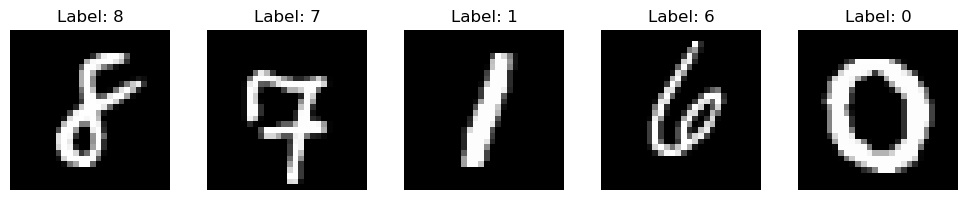

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(mnist_x_train[i, :, :, 0], cmap="gray")
    ax.set_title(f"Label: {mnist_y_train[i]}")
    ax.axis("off")
plt.tight_layout()

### Keras CNN 모델 만들기

**합성곱 층 → 맥스 풀링 층**을 반복한 다음 분류 출력층을 연결한다. 이미지의 공간 정보를 보존하는 것이 MLP와 가장 큰 차이다.

In [4]:
inputs = keras.Input(shape=(28, 28, 1))
x = layers.Conv2D(32, 3, padding="same", activation="relu", name="first_conv")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(10, activation="softmax")(x)

mnist_cnn = keras.Model(inputs, outputs, name="mnist_cnn")
mnist_cnn.summary()

I0000 00:00:1793414829.369183   35410 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9556 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "mnist_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ first_conv (Conv2D)             │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,962 (367.04 KB)

 Non-trainable params: 0 (0.00 B)

`Conv2D(32, 3)`은 3×3 커널을 가진 필터 32개를 사용한다. 따라서 **출력 채널 수는 32**다. `MaxPooling2D(2)`는 각 채널의 높이와 너비를 줄이고, `GlobalAveragePooling2D`는 채널마다 평균값 하나를 만든다.

**확인:** `summary()`에서 공간 크기는 작아지고 채널 수는 커지는지 살펴보자.

### 훈련·검증 곡선 확인

다중 클래스 분류이므로 정수 타깃에는 `sparse_categorical_crossentropy`를 사용한다. 정확도 하나만 보지 말고, 훈련·검증 곡선이 어떻게 다른지도 확인한다.

In [5]:
mnist_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

mnist_history = mnist_cnn.fit(
    mnist_x_train, mnist_y_train,
    validation_data=(mnist_x_val, mnist_y_val),
    epochs=4, batch_size=128, verbose=1,
)

Epoch 1/4
 72/422 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.1782 - loss: 2.1793

I0000 00:00:1793414832.280725   35534 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7495 - loss: 0.7868 - val_accuracy: 0.9155 - val_loss: 0.2850
Epoch 2/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9309 - loss: 0.2354 - val_accuracy: 0.9458 - val_loss: 0.1842
Epoch 3/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9480 - loss: 0.1733 - val_accuracy: 0.9582 - val_loss: 0.1409
Epoch 4/4
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9578 - loss: 0.1390 - val_accuracy: 0.9653 - val_loss: 0.1156


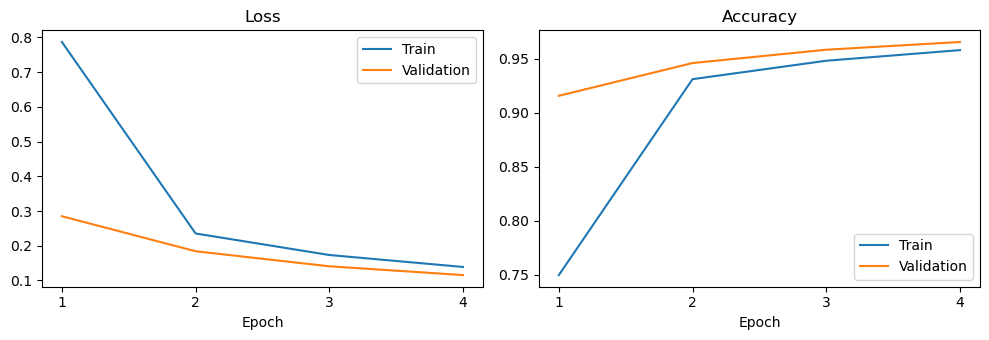

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

for key, title, ax in [("loss", "Loss", axes[0]), ("accuracy", "Accuracy", axes[1])]:
    epochs = range(1, len(mnist_history.history[key]) + 1)
    ax.plot(epochs, mnist_history.history[key], label="Train")
    ax.plot(epochs, mnist_history.history["val_" + key], label="Validation")
    ax.set_xlabel("Epoch")
    ax.set_xticks(range(1, 5))
    ax.set_title(title)
    ax.legend()

plt.tight_layout()

**생각해보기:** 훈련 손실이 감소하는데 검증 손실은 더 이상 감소하지 않는다면 무엇을 의심해야 할까? 모델 성능을 개선하려면 어떤 데이터를 기준으로 판단해야 할까?

### CNN이 만드는 특성맵 보기

한 장의 이미지를 첫 번째 `Conv2D` 층에 통과시키면 32개의 특성맵이 나온다. 각 맵은 **학습된 필터가 강조하는 위치와 특징**을 보여준다. 필터마다 무엇을 강조하는지는 훈련 결과에 따라 달라진다.

특성맵 모양: (1, 28, 28, 32)


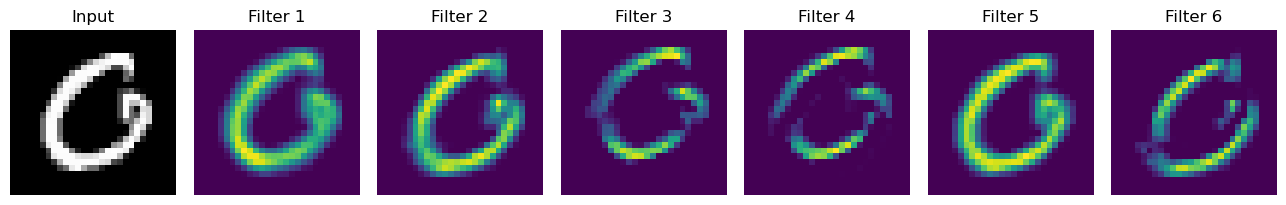

In [7]:
feature_model = keras.Model(mnist_cnn.input, mnist_cnn.get_layer("first_conv").output)
feature_maps = feature_model.predict(mnist_x_val[:1], verbose=0)
print("특성맵 모양:", feature_maps.shape)

fig, axes = plt.subplots(1, 7, figsize=(13, 2))
axes[0].imshow(mnist_x_val[0, :, :, 0], cmap="gray")
axes[0].set_title("Input")
for k in range(6):
    axes[k + 1].imshow(feature_maps[0, :, :, k], cmap="viridis")
    axes[k + 1].set_title(f"Filter {k+1}")
for ax in axes: ax.axis("off")
plt.tight_layout()

**관찰:** 필터마다 입력 이미지의 어떤 부분이 밝게 반응하는지 비교한다. 같은 필터가 이미지의 여러 위치에 적용된다는 점이 Dense 층과 다른 핵심이다.

## 합성곱과 맥스 풀링은 무엇을 계산할까?

### 작은 배열에 필터 적용하기

합성곱 층은 작은 필터를 이미지 위에서 이동시키며 위치별 값을 계산한다. 실습에서는 한 채널의 `5×5` 입력에 `3×3` 필터를 보폭 1, 패딩 없이 적용한다.

In [8]:
small_image = np.arange(25).reshape(5, 5)
edge_filter = np.array([[-1, 0, 1],
                        [-1, 0, 1],
                        [-1, 0, 1]])

conv_result = np.zeros((3, 3), dtype=int)
for row in range(3):
    for col in range(3):
        patch = small_image[row:row+3, col:col+3]
        conv_result[row, col] = np.sum(patch * edge_filter)

print("입력:\n", small_image)
print("필터:\n", edge_filter)
print("출력:\n", conv_result)

입력:
 [[ 0  1  2  3  4]
 [ 5  6  7  8  9]
 [10 11 12 13 14]
 [15 16 17 18 19]
 [20 21 22 23 24]]
필터:
 [[-1  0  1]
 [-1  0  1]
 [-1  0  1]]
출력:
 [[6 6 6]
 [6 6 6]
 [6 6 6]]


수학 공식을 외우기보다 **필터가 보는 지역의 크기**, **어디로 이동하는지**, **어떤 출력맵이 생기는지**에 집중하자. 딥러닝의 필터 가중치는 위 예시와 달리 훈련 중에 학습된다. (딥러닝에서 일반적으로 사용하는 연산은 엄밀히는 상관 연산 형태다.)

### 보폭과 패딩, 풀링의 출력 크기

`padding="valid"`는 가장자리에 값을 추가하지 않는다. `padding="same"`은 보폭이 1일 때 공간 크기를 유지하도록 패딩한다. 보폭이 2이면 공간 크기는 대체로 절반이 된다.

In [9]:
image = np.arange(1, 17).reshape(4, 4)
pooled = image.reshape(2, 2, 2, 2).max(axis=(1, 3))

print("원래 배열:\n", image)
print("2×2 맥스 풀링 결과:\n", pooled)

example_input = keras.Input(shape=(28, 28, 1))
print("valid:", layers.Conv2D(8, 3, padding="valid")(example_input).shape)
print("same: ", layers.Conv2D(8, 3, padding="same")(example_input).shape)
print("stride 2:", layers.Conv2D(8, 3, strides=2, padding="same")(example_input).shape)

원래 배열:
 [[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]
2×2 맥스 풀링 결과:
 [[ 6  8]
 [14 16]]
valid: (None, 26, 26, 8)
same:  (None, 28, 28, 8)
stride 2: (None, 14, 14, 8)


**정리:** 합성곱의 필터는 **학습할 가중치**가 있지만 맥스 풀링은 지역의 최댓값을 선택하므로 **학습할 파라미터가 없다**. 풀링으로 공간 크기를 줄인다고 앞선 합성곱 층의 파라미터 수까지 줄어드는 것은 아니다.

### 채널 수와 파라미터 수 비교

필터 수는 출력 채널 수를 결정한다. 필터의 크기와 입력 채널 수는 합성곱 층에 필요한 가중치 수에 영향을 준다. 같은 공간 크기를 다루더라도 Dense 층과 합성곱 층의 파라미터 수는 크게 다를 수 있다.

In [10]:
conv_example = layers.Conv2D(32, 3, use_bias=False)
conv_example(keras.Input(shape=(28, 28, 1)))

dense_example = layers.Dense(32, use_bias=False)
dense_example(keras.Input(shape=(28*28,)))

print("Conv2D 파라미터:", conv_example.count_params())
print("Dense 파라미터:", dense_example.count_params())

Conv2D 파라미터: 288
Dense 파라미터: 25088


## PyTorch로 같은 CNN 구성하기

Keras와 PyTorch는 서로 다른 신경망 원리가 아니다. 다만 이미지 텐서의 채널 축 위치와 훈련 방식이 다르다.

- Keras: `(배치, 높이, 너비, 채널)` — NHWC
- PyTorch: `(배치, 채널, 높이, 너비)` — NCHW

PyTorch의 `nn.CrossEntropyLoss`는 **logits**를 입력으로 받으므로 모델의 마지막 층에 Softmax를 추가하지 않는다.

In [11]:
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("장치:", device)

torch_x_train = torch.from_numpy(mnist_x_train).permute(0, 3, 1, 2)
torch_x_val = torch.from_numpy(mnist_x_val).permute(0, 3, 1, 2)
torch_x_test = torch.from_numpy(mnist_x_test).permute(0, 3, 1, 2)

train_loader = DataLoader(TensorDataset(torch_x_train, torch.from_numpy(mnist_y_train).long()),
                          batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(torch_x_val, torch.from_numpy(mnist_y_val).long()),
                        batch_size=256)
test_loader = DataLoader(TensorDataset(torch_x_test, torch.from_numpy(mnist_y_test).long()),
                         batch_size=256)

print("Keras 첫 배치 차원:", mnist_x_train[:128].shape)
print("PyTorch 첫 배치 차원:", next(iter(train_loader))[0].shape)

장치: cuda
Keras 첫 배치 차원: (128, 28, 28, 1)
PyTorch 첫 배치 차원: torch.Size([128, 1, 28, 28])


### `forward()`에서 층을 직접 연결하기

모델의 층은 `__init__()`에서 정의하고, `forward()`에서 계산 순서를 명시한다.

In [12]:
class TorchMNISTCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.relu = nn.ReLU()
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.output = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = self.relu(self.conv3(x))
        x = self.gap(x)
        x = torch.flatten(x, start_dim=1)
        return self.output(x)  # logits

torch_cnn = TorchMNISTCNN().to(device)
print(torch_cnn)

TorchMNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (gap): AdaptiveAvgPool2d(output_size=1)
  (output): Linear(in_features=128, out_features=10, bias=True)
)


### 훈련과 검증

PyTorch에서는 `zero_grad() → forward → loss → backward() → step()`을 직접 작성한다. 검증 때는 `eval()`로 모드를 바꾸고 기울기 계산을 끈다.

In [13]:
def run_torch_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if training:
                optimizer.zero_grad()
            logits = model(xb)
            loss = loss_fn(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(xb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(xb)
    return total_loss / total, correct / total

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(torch_cnn.parameters(), lr=1e-3)

torch_history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
for epoch in range(3):
    tr_loss, tr_acc = run_torch_epoch(torch_cnn, train_loader, loss_fn, optimizer)
    va_loss, va_acc = run_torch_epoch(torch_cnn, val_loader, loss_fn)
    for key, value in [("loss", tr_loss), ("accuracy", tr_acc),
                       ("val_loss", va_loss), ("val_accuracy", va_acc)]:
        torch_history[key].append(value)
    print(f"epoch {epoch+1}: loss={tr_loss:.3f}, accuracy={tr_acc:.3f}, "
          f"val_loss={va_loss:.3f}, val_accuracy={va_acc:.3f}")

epoch 1: loss=0.972, accuracy=0.683, val_loss=0.379, val_accuracy=0.888
epoch 2: loss=0.272, accuracy=0.918, val_loss=0.217, val_accuracy=0.935
epoch 3: loss=0.189, accuracy=0.942, val_loss=0.163, val_accuracy=0.950


**검증:** 같은 CNN 개념으로 모델을 구성했지만 두 프레임워크의 결과가 정확히 같을 필요는 없다. 초기 가중치와 훈련 방식 등이 다르기 때문이다. **비교할 때는 사용한 데이터와 평가 기준을 먼저 확인한다.**

### MNIST 테스트 데이터에서 최종 평가

훈련과 검증을 마친 후에만 테스트 데이터로 평가한다. 테스트 결과를 보고 모델을 반복해서 수정하면 테스트 데이터가 사실상 검증 데이터처럼 사용된다.

In [14]:
keras_test_loss, keras_test_acc = mnist_cnn.evaluate(mnist_x_test, mnist_y_test, verbose=0)
torch_test_loss, torch_test_acc = run_torch_epoch(torch_cnn, test_loader, loss_fn)
print(f"Keras    테스트 정확도: {keras_test_acc:.3f}")
print(f"PyTorch  테스트 정확도: {torch_test_acc:.3f}")

Keras    테스트 정확도: 0.968
PyTorch  테스트 정확도: 0.953


## 작은 이미지 데이터셋: 고양이와 개 분류

CIFAR-10에서 **고양이(cat)와 개(dog) 두 클래스**만 추출하여 이진 분류 문제를 만든다. 이를 통해 CNN 기준 모델과 데이터 증식, 전이 학습을 비교한다.

**주의:** CIFAR-10 이미지는 32×32 픽셀로 매우 작다. 이미지 해상도와 데이터의 특성이 모델 성능에 영향을 줄 수 있다.

In [16]:
from keras.datasets import cifar10

(cifar_x_train_all, cifar_y_train_all), (cifar_x_test_all, cifar_y_test_all) = cifar10.load_data()
cifar_y_train_all = cifar_y_train_all.reshape(-1)
cifar_y_test_all = cifar_y_test_all.reshape(-1)

# CIFAR-10: cat=3, dog=5. 타깃 0=cat, 1=dog.
rng = np.random.default_rng(42)
train_ids, val_ids, test_ids = [], [], []
for original_class in (3, 5):
    tr = rng.permutation(np.flatnonzero(cifar_y_train_all == original_class))
    te = rng.permutation(np.flatnonzero(cifar_y_test_all == original_class))
    train_ids.extend(tr[:1000])
    val_ids.extend(tr[1000:1250])
    test_ids.extend(te[:300])

train_ids = rng.permutation(train_ids)
val_ids = rng.permutation(val_ids)
test_ids = rng.permutation(test_ids)

catdog_x_train = cifar_x_train_all[train_ids].astype("float32")
catdog_y_train = (cifar_y_train_all[train_ids] == 5).astype("float32")
catdog_x_val = cifar_x_train_all[val_ids].astype("float32")
catdog_y_val = (cifar_y_train_all[val_ids] == 5).astype("float32")
catdog_x_test = cifar_x_test_all[test_ids].astype("float32")
catdog_y_test = (cifar_y_test_all[test_ids] == 5).astype("float32")

print("훈련 / 검증 / 테스트:", len(train_ids), len(val_ids), len(test_ids))
print("이미지 모양:", catdog_x_train.shape[1:])

훈련 / 검증 / 테스트: 2000 500 600
이미지 모양: (32, 32, 3)


고양이와 개 중 하나를 예측하는 **이진 분류**다. 따라서 출력 유닛 하나와 Sigmoid, 이진 교차엔트로피를 사용할 수 있다. 이미지의 해상도가 작으므로 작은 CNN으로 먼저 기준 모델을 만든다.

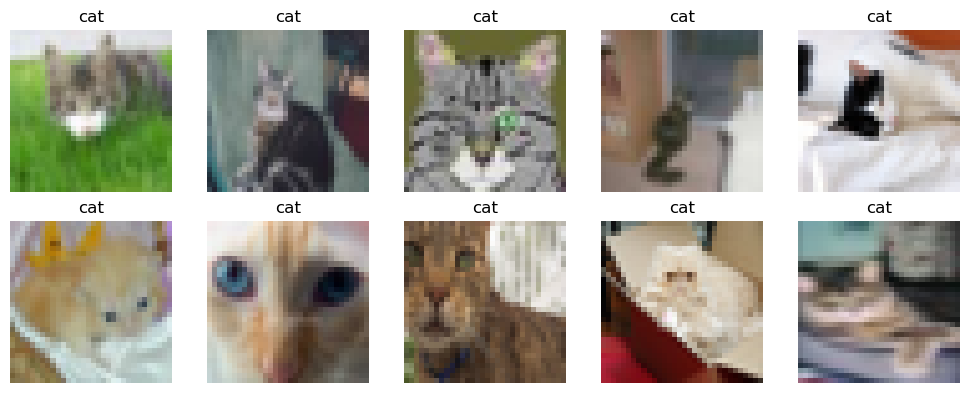

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.flat, catdog_x_train[:10], catdog_y_train[:10]):
    ax.imshow(image.astype("uint8"))
    ax.set_title("dog" if label == 1 else "cat")
    ax.axis("off")
plt.tight_layout()

### 기준 CNN과 데이터 증식 CNN 비교

데이터 증식(augmentation)은 **훈련 이미지를 반전·회전 등으로 조금씩 바꾸어** 모델이 특정 사진에만 의존하지 않도록 돕는다. 타깃의 의미를 보존하는 변환이어야 한다. 데이터 증식은 별도의 실제 사진을 새로 수집하는 것과는 다르다.

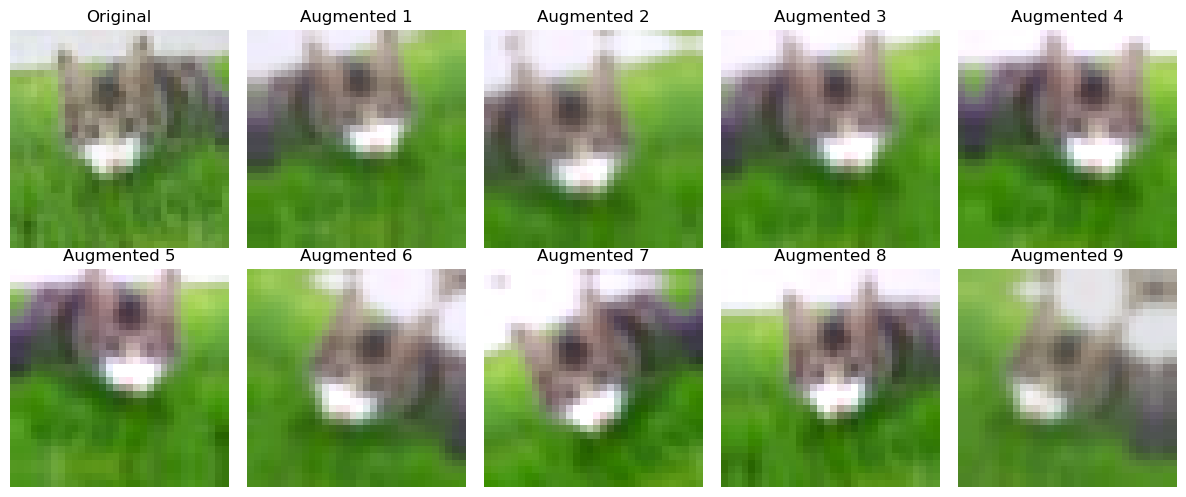

In [18]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomTranslation(0.10, 0.10),
    layers.RandomZoom(0.07),
    layers.RandomContrast(0.5),
], name="augmentation")

image = catdog_x_train[:1]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

axes[0].imshow(image[0].astype("uint8"))
axes[0].set_title("Original")

for i, ax in enumerate(axes[1:], start=1):
    changed = augmentation(image, training=True).numpy()[0]
    ax.imshow(np.clip(changed, 0, 255).astype("uint8"))
    ax.set_title(f"Augmented {i}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

**관찰:** 같은 이미지여도 증식할 때마다 달라진다. 훈련에서는 `training=True`로 작동하지만, 검증·테스트에서는 증식을 끄고 변형하지 않은 이미지로 평가해야 한다.

In [19]:
def build_catdog_model(use_augmentation=False):
    inputs = keras.Input(shape=(32, 32, 3))
    x = inputs
    if use_augmentation:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomRotation(0.05)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

baseline_catdog = build_catdog_model(use_augmentation=False)
augmented_catdog = build_catdog_model(use_augmentation=True)

history_baseline = baseline_catdog.fit(
    catdog_x_train, catdog_y_train,
    validation_data=(catdog_x_val, catdog_y_val),
    epochs=5, batch_size=64, verbose=1,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
)
history_augmented = augmented_catdog.fit(
    catdog_x_train, catdog_y_train,
    validation_data=(catdog_x_val, catdog_y_val),
    epochs=5, batch_size=64, verbose=1,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
)

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.5160 - loss: 0.6944 - val_accuracy: 0.5100 - val_loss: 0.6919
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5165 - loss: 0.6920 - val_accuracy: 0.5340 - val_loss: 0.6890
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5520 - loss: 0.6904 - val_accuracy: 0.5700 - val_loss: 0.6856
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5470 - loss: 0.6880 - val_accuracy: 0.6160 - val_loss: 0.6783
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5590 - loss: 0.6820 - val_accuracy: 0.6140 - val_loss: 0.6713
Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.4930 - loss: 0.6942 - val_accuracy: 0.5580 - val_loss: 0.6923
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5355 - loss: 0.6926 - val_accuracy: 0.5880 - val_loss: 0.6901
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5555 - loss: 0.6912 - val_accuracy: 0.5320 - val_loss: 0.687

### 비교는 검증 데이터로

두 모델 모두 같은 훈련·검증 데이터를 사용해야 한다. 데이터 증식이 항상 성능을 높이는 것은 아니므로 **검증 손실과 검증 정확도**를 보고 판단한다. 조기 종료 콜백의 `restore_best_weights=True`는 검증 손실이 가장 좋았던 가중치를 복원한다. 테스트셋은 아직 사용하지 않는다.

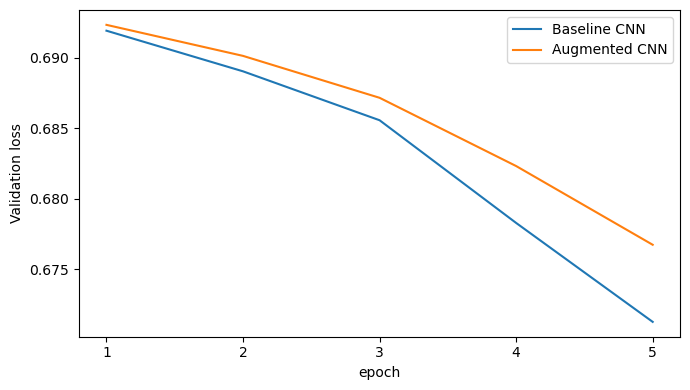

In [20]:
plt.figure(figsize=(7, 4))
for label, h in [("Baseline CNN", history_baseline), ("Augmented CNN", history_augmented)]:
    epochs = range(1, len(h.history["val_loss"]) + 1)
    plt.plot(epochs, h.history["val_loss"], label=label)
plt.xlabel("epoch")
plt.xticks(range(1, 6))
plt.ylabel("Validation loss")
plt.legend()
plt.tight_layout()

### 전이 학습: 이미 훈련된 CNN 재활용

ImageNet으로 사전훈련된 **Xception**의 합성곱 기저를 재사용하여 전이 학습을 실습한다. Xception은 **채널 분리 합성곱·배치 정규화·잔차 연결**을 조합한 CNN으로, 마지막 절에서 구조를 살펴본다.

- `weights="imagenet"`: 사전훈련 가중치 사용
- `include_top=False`: ImageNet 분류 출력층 제외
- `transfer_base.trainable=False`: 사전훈련 기저 동결
- 새로운 이진 분류층을 추가하여 고양이·개를 분류함

**입력 처리:** Xception의 기본 입력 크기는 299×299이지만 분류층을 제외하면 96×96도 사용할 수 있다. 여기서는 32×32 CIFAR-10 이미지를 96×96으로 확대하고 픽셀값을 `[-1, 1]` 범위로 조정한다. 확대한다고 원본 이미지에 없던 세부 정보가 새로 생기는 것은 아니다.

**실행 참고:** Xception은 모델이 크므로 CPU에서는 훈련 시간이 길 수 있다. 사전훈련 가중치를 처음 사용할 때는 다운로드가 필요하며, 다운로드할 수 없다면 이 부분을 건너뛰고 다음 컴퓨터 비전 실습을 계속한다.

In [21]:
transfer_model, transfer_history, transfer_base = None, None, None
try:
    transfer_base = keras.applications.Xception(
        input_shape=(96, 96, 3), include_top=False, weights="imagenet"
    )
    transfer_base.trainable = False

    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.Resizing(96, 96)(x)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)  # Xception 입력 범위 [-1, 1]
    x = transfer_base(x, training=False)  # 미세 조정 중에도 BatchNorm은 추론 모드
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    transfer_model = keras.Model(inputs, outputs, name="catdog_xception_transfer")
    transfer_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy", metrics=["accuracy"],
    )
    transfer_history = transfer_model.fit(
        catdog_x_train, catdog_y_train,
        validation_data=(catdog_x_val, catdog_y_val),
        epochs=4, batch_size=16, verbose=1,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)],
    )
except Exception as exc:
    print("전이 학습 구간을 실행하지 못했습니다:", type(exc).__name__, str(exc)[:200])

Epoch 1/4


2026-10-31 11:47:39.962237: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:40.103688: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:40.604543: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:40.751268: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:41.286958: E external/local_xla/xla/stream_

121/125 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7179 - loss: 0.5350

2026-10-31 11:47:49.117486: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:49.264913: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:49.414433: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:49.554295: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:50.046533: E external/local_xla/xla/stream_

125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 75ms/step - accuracy: 0.7595 - loss: 0.4825 - val_accuracy: 0.8260 - val_loss: 0.3943
Epoch 2/4
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8235 - loss: 0.3890 - val_accuracy: 0.8280 - val_loss: 0.3798
Epoch 3/4
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8415 - loss: 0.3636 - val_accuracy: 0.8340 - val_loss: 0.3745
Epoch 4/4
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8545 - loss: 0.3348 - val_accuracy: 0.8300 - val_loss: 0.3671


**판단:** 사전훈련 모델이 좋은 결과를 보장하지는 않는다. 사전훈련 데이터와 목표 데이터가 얼마나 비슷한지, 입력 이미지의 해상도, 사용하는 데이터의 양, 전처리 방식이 결과에 영향을 준다.

### 미세 조정(fine-tuning)은 언제 필요한가?

특성 추출 단계에서는 Xception 기저를 **동결**하고 새로운 분류층만 훈련한다. 미세 조정에서는 Xception의 **마지막 일부 층만 동결 해제**하고 작은 학습률로 추가 훈련할 수 있다. 훈련 가능한 층을 바꾼 뒤에는 다시 `compile()`해야 한다.

Xception에는 `BatchNormalization` 층이 많이 포함되어 있다. 미세 조정 시 배치 통계가 크게 바뀌지 않도록 이 층은 동결하고, 앞에서 사용한 `transfer_base(x, training=False)` 호출도 유지한다.

아래 코드는 선택 실습이다. `RUN_FINE_TUNING=True`로 바꿀 때만 실행된다. CPU에서는 실행 시간이 길 수 있다.

In [22]:
RUN_FINE_TUNING = False
if RUN_FINE_TUNING and transfer_model is not None:
    transfer_base.trainable = True
    for layer in transfer_base.layers[:-20]:
        layer.trainable = False
    for layer in transfer_base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    print("미세 조정 대상 가중치 수:", len(transfer_base.trainable_weights))
    transfer_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy", metrics=["accuracy"],
    )
    transfer_history = transfer_model.fit(
        catdog_x_train, catdog_y_train,
        validation_data=(catdog_x_val, catdog_y_val),
        epochs=2, batch_size=16, verbose=1,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)],
    )

### 마지막으로 테스트 데이터에서 평가

검증 데이터에서 선택한 모델만 테스트한다. 서로 다른 접근법의 성능을 비교할 때 **같은 검증셋과 같은 평가 기준**을 사용한다.

In [23]:
candidates = {
    "기준 CNN": (baseline_catdog, history_baseline),
    "증식 CNN": (augmented_catdog, history_augmented),
}
if transfer_history is not None:
    candidates["전이 학습"] = (transfer_model, transfer_history)

for name, (_, h) in candidates.items():
    print(name, "최소 검증 손실:", round(min(h.history["val_loss"]), 4),
          "최종 검증 정확도:", round(h.history["val_accuracy"][-1], 4))

best_name = min(candidates, key=lambda key: min(candidates[key][1].history["val_loss"]))
best_model = candidates[best_name][0]
print("검증 손실로 선택한 모델:", best_name)

catdog_test_loss, catdog_test_acc = best_model.evaluate(
    catdog_x_test, catdog_y_test, verbose=0
)
print(f"선택 모델의 테스트 정확도: {catdog_test_acc:.3f}")

기준 CNN 최소 검증 손실: 0.6713 최종 검증 정확도: 0.614
증식 CNN 최소 검증 손실: 0.6767 최종 검증 정확도: 0.61
전이 학습 최소 검증 손실: 0.3671 최종 검증 정확도: 0.83
검증 손실로 선택한 모델: 전이 학습


2026-10-31 11:47:58.825000: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:58.974933: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:59.118843: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:59.258858: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 11:47:59.411116: E external/local_xla/xla/stream_

선택 모델의 테스트 정확도: 0.812


**해석:** 어떤 모델이 선택되었는가? 데이터 증식이 검증 손실을 줄였는가? 전이 학습의 효과가 불분명하다면 가능한 이유를 두 가지 생각해보자.

## 컴퓨터 비전: 무엇을 예측하는가?

컴퓨터 비전의 대표적인 문제에는 **이미지 분류, 객체 탐지, 이미지 분할**이 있다. 입력이 같은 이미지라도 타깃의 의미와 출력 형태는 다르다.

| 문제 | 모델의 예측 | 예시 |
|---|---|---|
| 이미지 분류 | 이미지 전체의 클래스 | 사진은 고양이인가? |
| 객체 탐지 | 객체의 클래스와 경계 상자 | 고양이가 어디에 있는가? |
| 시맨틱 분할 | 픽셀마다 클래스 | 어느 픽셀이 고양이인가? |
| 인스턴스 분할 | 픽셀의 클래스와 개별 객체 구별 | 고양이 두 마리를 각각 구분할 수 있는가? |

**참고:** 객체가 여러 개라면 다중 라벨 분류와 객체 탐지를 구분해야 한다. 다중 라벨 분류는 존재하는 클래스들을 알려주지만 개별 객체의 **위치**는 제공하지 않는다.

### 분류·탐지·분할의 타깃을 그림으로 확인

다음 인공 예제에서는 화면에 사각형과 원을 배치한다. 이 그림은 실제 데이터셋의 주석이 아니라 **각 문제에서 요구되는 정답의 형태를 설명하려는 시각화**다.

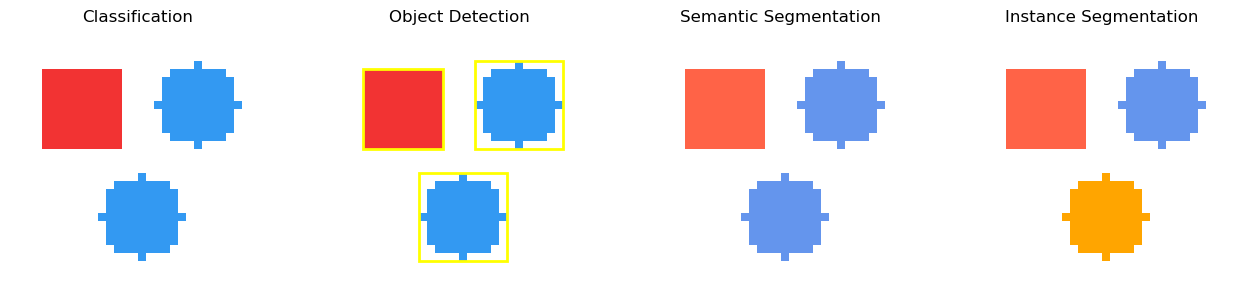

In [59]:
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap

canvas = np.ones((32, 32, 3), dtype="float32")
semantic_mask = np.zeros((32, 32), dtype="int32")
instance_mask = np.zeros((32, 32), dtype="int32")

# 사각형 1개
rect = np.zeros((32, 32), dtype=bool)
rect[5:15, 4:14] = True

# 원 2개
r, c = np.ogrid[:32, :32]
circle1 = (r - 9)**2 + (c - 23)**2 <= 5**2
circle2 = (r - 23)**2 + (c - 16)**2 <= 5**2

# 시맨틱 분할: 같은 클래스는 같은 값
semantic_mask[rect] = 1
semantic_mask[circle1] = 2
semantic_mask[circle2] = 2

# 인스턴스 분할: 객체마다 다른 값
instance_mask[rect] = 1
instance_mask[circle1] = 2
instance_mask[circle2] = 3

# 원본 이미지
canvas[rect] = [0.95, 0.2, 0.2]
canvas[circle1 | circle2] = [0.2, 0.6, 0.95]

# 분할 결과의 색상
semantic_cmap = ListedColormap(["white", "tomato", "cornflowerblue"])
instance_cmap = ListedColormap(["white", "tomato", "cornflowerblue", "orange"])

fig, axes = plt.subplots(1, 4, figsize=(13, 3))

# 1. 이미지 분류
axes[0].imshow(canvas)
axes[0].set_title("Classification")

# 2. 객체 탐지
axes[1].imshow(canvas)
for x, y, w, h in [
    (3.5, 4.5, 10, 10),
    (17.5, 3.5, 11, 11),
    (10.5, 17.5, 11, 11),
]:
    axes[1].add_patch(
        Rectangle((x, y), w, h, fill=False,
                  edgecolor="yellow", lw=2)
    )
axes[1].set_title("Object Detection")

# 3. 시맨틱 분할
axes[2].imshow(semantic_mask, cmap=semantic_cmap,
               vmin=-0.5, vmax=2.5)
axes[2].set_title("Semantic Segmentation")

# 4. 인스턴스 분할
axes[3].imshow(instance_mask, cmap=instance_cmap,
               vmin=-0.5, vmax=3.5)
axes[3].set_title("Instance Segmentation")

for ax in axes:
    ax.axis("off")

plt.tight_layout()

## 객체 탐지: 물체의 종류와 위치를 함께 예측하기

이미지 분류는 **이미지 전체의 클래스**를 예측한다. 반면 객체 탐지는 이미지 안에 있는 **각 객체의 클래스와 위치**를 함께 예측한다.

여기서는 모델을 새로 훈련하지 않고, COCO 데이터셋으로 사전훈련된 **Faster R-CNN** 모델을 사용해 탐지 결과를 살펴본다. 실습의 목적은 높은 성능을 얻는 것이 아니라 **탐지 모델의 출력이 무엇을 의미하는지 이해하는 것**이다.

In [25]:
import matplotlib.cbook as cbook
from PIL import Image
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights

sample_path = cbook.get_sample_data('grace_hopper.jpg', asfileobj=False)
detection_image = Image.open(sample_path).convert('RGB')

detection_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
detector = fasterrcnn_resnet50_fpn(weights=weights).to(detection_device)
detector.eval()

detection_transform = weights.transforms()
coco_categories = weights.meta['categories']

print('Detection device:', detection_device)
print('Sample image size:', detection_image.size)

Detection device: cuda
Sample image size: (512, 600)


### 경계 상자와 신뢰도 확인

객체 탐지 모델은 보통 다음 세 가지를 함께 출력한다.

- `boxes`: 경계 상자 좌표 `(x1, y1, x2, y2)`
- `labels`: 예측된 클래스 인덱스
- `scores`: 각 예측의 신뢰도

실습에서는 신뢰도(`score`)가 일정 기준 이상인 예측만 화면에 표시한다.

      person: 0.999
         tie: 0.955


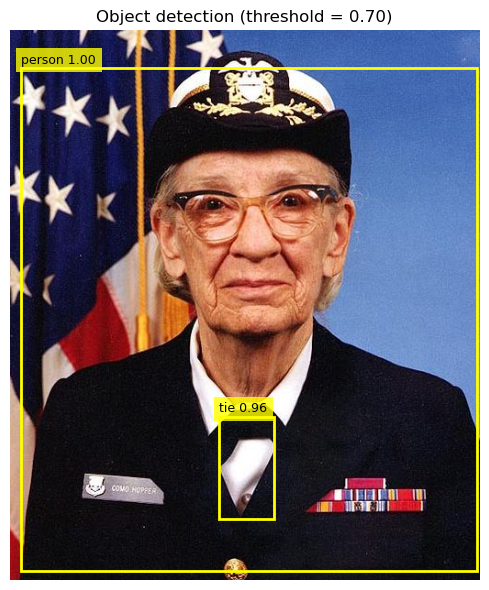

In [38]:
def run_detection(image, score_threshold=0.70):
    x = detection_transform(image).unsqueeze(0).to(detection_device)
    with torch.no_grad():
        output = detector(x)[0]

    boxes = output['boxes'].detach().cpu().numpy()
    labels = output['labels'].detach().cpu().numpy()
    scores = output['scores'].detach().cpu().numpy()
    keep = scores >= score_threshold
    return boxes[keep], labels[keep], scores[keep]


def show_detection(ax, image, boxes, labels, scores, title):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box
        rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1,
                             fill=False, edgecolor='yellow', linewidth=2)
        ax.add_patch(rect)
        ax.text(x1, max(y1 - 5, 5),
                f"{coco_categories[label]} {score:.2f}",
                color='black', fontsize=9,
                bbox=dict(facecolor='yellow', alpha=0.8, edgecolor='none'))

boxes_07, labels_07, scores_07 = run_detection(detection_image, score_threshold=0.70)

fig, ax = plt.subplots(figsize=(6, 6))
show_detection(ax, detection_image, boxes_07, labels_07, scores_07,
               'Object detection (threshold = 0.70)')
plt.tight_layout()

for label, score in zip(labels_07, scores_07):
    print(f"{coco_categories[label]:>12s}: {score:.3f}")

**관찰:** 이미지 분류였다면 `person`처럼 이미지 전체에 대한 하나의 클래스를 출력하면 된다. 하지만 객체 탐지에서는 **어디에 사람이 있는지**를 나타내는 경계 상자도 함께 필요하다.

같은 이미지라도 신뢰도 임곗값을 어떻게 정하느냐에 따라 화면에 남는 예측이 달라질 수 있다.

### 신뢰도 임곗값을 바꾸면 무엇이 달라질까?

임곗값을 낮추면 더 많은 후보를 남기고, 높이면 더 확실한 예측만 남긴다. 이 값은 **오탐(false positive)**과 **미탐(false negative)** 사이의 균형과 연결된다.

Number of detections at 0.30: 7
Number of detections at 0.80: 2


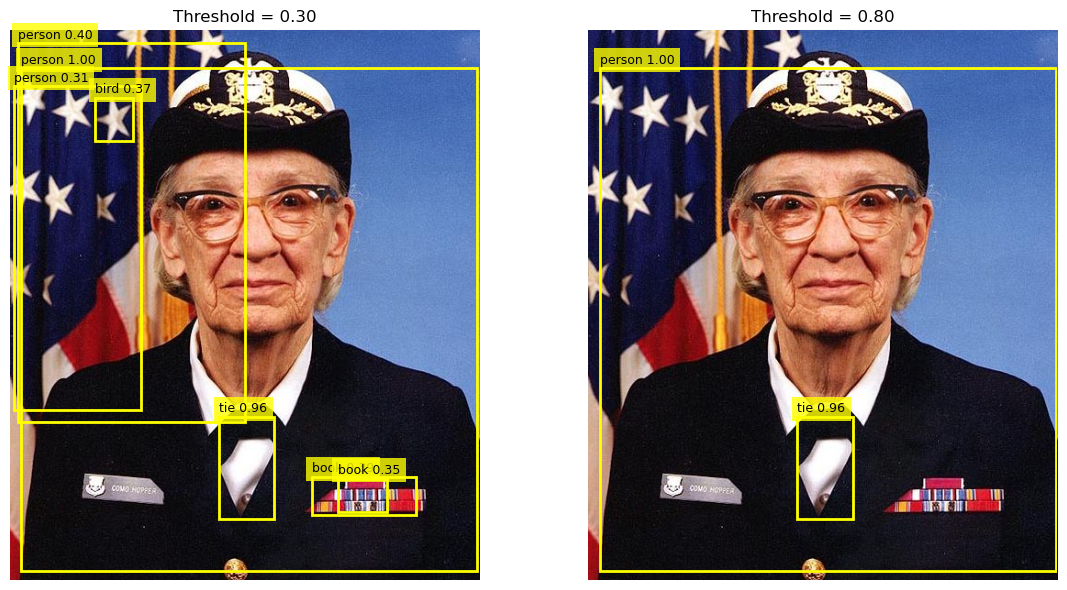

In [27]:
boxes_03, labels_03, scores_03 = run_detection(detection_image, score_threshold=0.30)
boxes_08, labels_08, scores_08 = run_detection(detection_image, score_threshold=0.80)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
show_detection(axes[0], detection_image, boxes_03, labels_03, scores_03,
               'Threshold = 0.30')
show_detection(axes[1], detection_image, boxes_08, labels_08, scores_08,
               'Threshold = 0.80')
plt.tight_layout()

print('Number of detections at 0.30:', len(scores_03))
print('Number of detections at 0.80:', len(scores_08))

**왜 객체 탐지가 컴퓨터 비전의 중요한 응용일까?**

- 자율주행에서는 보행자, 자동차, 신호등의 **위치**가 필요하다.
- 의료 영상에서는 병변이 **어디에 있는지**를 표시해야 한다.
- 보안 영상에서는 사람이나 물체의 **존재와 위치**를 함께 확인해야 한다.

즉 객체 탐지는 **무엇이 있는가?**뿐 아니라 **어디에 있는가?**까지 답하려는 문제다.

## CNN 아키텍처의 세 가지 개선 아이디어

**잔차 연결, 배치 정규화, 채널 분리 합성곱**은 CNN 구조를 개선할 때 활용하는 방법이다. 큰 네트워크를 새로 훈련하기보다 **각 코드가 어떤 문제를 해결하는지** 확인한다.

### 잔차 연결: 입력을 출력에 더하기

잔차 연결(residual connection)은 블록을 통과한 값에 블록의 입력을 더한다. 더할 텐서의 **모양이 같아야 한다**. 모양이 다르면 `1×1` 합성곱 등으로 맞춘다.

In [28]:
res_inputs = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(16, 3, padding="same", activation="relu")(res_inputs)
skip = x  # 블록 입력 저장
x = layers.Conv2D(16, 3, padding="same")(x)
x = layers.Add()([x, skip])
x = layers.Activation("relu")(x)
res_model = keras.Model(res_inputs, x)
print("입력:", res_model.input_shape, "출력:", res_model.output_shape)

입력: (None, 32, 32, 3) 출력: (None, 32, 32, 16)


**확인:** 만약 두 번째 합성곱 층의 필터 수가 32라면 `skip`의 채널 16과 달라져 그대로는 더할 수 없다. 이때 `Conv2D(32, 1)` 같은 층으로 `skip`의 채널 수를 맞출 수 있다.

### 배치 정규화: 중간 출력의 크기 조정

배치 정규화(batch normalization)는 층의 중간 출력에 정규화를 적용한다. 훈련과 평가 모드의 동작이 다르므로 전이 학습에서 동결 여부에 주의해야 한다.

In [29]:
bn_inputs = keras.Input(shape=(32, 32, 3))
x = layers.Conv2D(16, 3, padding="same", use_bias=False)(bn_inputs)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
bn_model = keras.Model(bn_inputs, x)
print("출력 모양:", bn_model.output_shape)

출력 모양: (None, 32, 32, 16)


### 채널 분리 합성곱: 적은 파라미터로 처리하기

`SeparableConv2D`는 채널별 합성곱(depthwise)과 1×1 합성곱(pointwise)을 결합한다. 일반 `Conv2D`와 비교해 학습할 가중치 수를 줄일 수 있다. **연산량이 적다는 사실만으로 모든 하드웨어에서 항상 더 빠르다고 보장할 수는 없다.**

In [30]:
comparison_input = keras.Input(shape=(32, 32, 3))
normal_conv = layers.Conv2D(64, 3, use_bias=False)
separable_conv = layers.SeparableConv2D(64, 3, use_bias=False)
normal_conv(comparison_input)
separable_conv(comparison_input)

print("Conv2D 가중치 수:", normal_conv.count_params())
print("SeparableConv2D 가중치 수:", separable_conv.count_params())

Conv2D 가중치 수: 1728
SeparableConv2D 가중치 수: 219


**해석:** 두 층의 출력 채널 수는 64로 같지만 파라미터 수는 다르다. 모델 설계에서는 정확도뿐 아니라 데이터 양·연산량·실행 시간도 함께 고려한다.

### Xception: 세 가지 개선 아이디어를 결합한 CNN

Xception은 **잔차 연결, 배치 정규화, 채널 분리 합성곱**을 하나의 아키텍처에 함께 사용한다. 큰 구조는 세 부분으로 나눠 볼 수 있다.

| 부분 | 주요 역할 |
|---|---|
| **Entry Flow** | 일반 합성곱으로 초기 특성을 추출한 후 채널 분리 합성곱과 풀링으로 공간 크기를 줄인다. |
| **Middle Flow** | 채널 분리 합성곱과 잔차 연결이 있는 블록을 **8회 반복**해 특성을 가공한다. |
| **Exit Flow** | 특성을 더 높은 수준으로 변환하고 최종 **2048채널 특성맵**을 만든다. |

중간 블록의 핵심 관계는 다음처럼 단순화할 수 있다. 실제 층에는 활성화 함수가 들어가고, 블록 종류에 따라 차원 조정이나 다운샘플링이 추가된다.

```text
                     ┌──────── 잔차 연결 ────────┐
입력 x ───────────┤                           Add → 출력
                     └→ (SeparableConv2D → BN) × 3 ──┘
```

- **`SeparableConv2D`**: 공간 필터링과 채널 결합을 나누어 수행한다.
- **`BatchNormalization`**: 합성곱의 중간 출력을 정규화한다.
- **`Add`**: 변환된 특성에 블록 입력을 더하는 잔차 연결이다.

앞에서 사용한 `include_top=False`는 Xception의 ImageNet 분류층을 제외하고 **특성 추출 부분만** 가져온다는 뜻이다. 여기에 `GlobalAveragePooling2D`와 이진 분류 출력층을 연결하여 고양이·개 분류에 활용했다.

**질문:** 이 세 가지 기법의 역할이 서로 다른데도 하나의 블록에서 함께 쓰이는 이유는 무엇일까?

In [31]:
# 전이 학습에서 불러온 실제 Xception 층의 구성을 살펴본다.
if transfer_base is not None:
    for cls in (layers.SeparableConv2D, layers.BatchNormalization, layers.Add):
        count = sum(isinstance(layer, cls) for layer in transfer_base.layers)
        print(f"{cls.__name__}: {count}")
    print("Xception feature shape:", transfer_base.output_shape)
else:
    print("Xception 모델이 로드되지 않아 구조 확인을 건너뜁니다.")

SeparableConv2D: 34
BatchNormalization: 40
Add: 12
Xception feature shape: (None, 3, 3, 2048)


## Keras와 PyTorch에서 같은 개념 찾기

| 개념 | Keras | PyTorch |
|---|---|---|
| 2차원 합성곱 | `layers.Conv2D` | `nn.Conv2d` |
| 맥스 풀링 | `layers.MaxPooling2D` | `nn.MaxPool2d` |
| 전역 평균 풀링 | `layers.GlobalAveragePooling2D` | `nn.AdaptiveAvgPool2d(1)` 후 펼치기 |
| 배치 정규화 | `layers.BatchNormalization` | `nn.BatchNorm2d` |
| 채널 분리 합성곱 | `layers.SeparableConv2D` | depthwise `nn.Conv2d(groups=입력채널)` + pointwise `nn.Conv2d(1)` |
| 잔차 연결 | `layers.Add()` | `x + skip` |
| 사전훈련 모델 재사용 | `keras.applications` | `torchvision.models` |

**주의:** PyTorch 합성곱의 이미지 입력은 NCHW, Keras의 기본 이미지 입력은 NHWC다. 마지막 분류층의 PyTorch `CrossEntropyLoss`는 logits를 기대한다.

## PyTorch 실습: 단순화한 Xception으로 이미지 분류하기

세 가지 CNN 개선 기법을 하나의 모델에 결합한다. **채널 분리 합성곱**은 연산을 나누어 수행하고, **배치 정규화**는 중간 출력을 정규화하며, **잔차 연결**은 블록 입력을 출력에 더한다.

여기서는 Xception의 **핵심 설계 아이디어만 가져온 작은 모델**을 직접 구현한다. 실제 Xception의 Entry·Middle·Exit Flow와 층 구성, 사전훈련 가중치를 그대로 재현한 모델은 아니다. 위에서 사용한 ImageNet 사전훈련 Xception과 달리 **처음부터 훈련**한다.

**질문:** 세 가지 기법을 하나의 잔차 블록으로 구현하려면 `forward()`에서 무엇을 더해야 할까?

### 채널 분리 합성곱과 잔차 블록 구현

- `groups=in_channels`인 `3×3 Conv2d`는 채널마다 별도의 공간 필터를 적용한다(Depthwise).
- `1×1 Conv2d`는 채널을 결합해 출력 채널을 만든다(Pointwise).
- 두 경로의 출력 모양이 다르면 `1×1 Conv2d`로 잔차 경로의 채널·공간 크기를 맞춘다.

아래 잔차 블록은 학습 가능한 두 개의 채널 분리 합성곱과 배치 정규화를 포함한다.

In [32]:
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.depthwise = nn.Conv2d(
            in_channels, in_channels, kernel_size=3, padding=1,
            groups=in_channels, bias=False
        )
        self.pointwise = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)

    def forward(self, x):
        x = self.depthwise(x)
        return self.pointwise(x)


class MiniXceptionBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.main = nn.Sequential(
            nn.ReLU(),
            DepthwiseSeparableConv(in_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            DepthwiseSeparableConv(out_channels, out_channels),
            nn.BatchNorm2d(out_channels),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1) if stride == 2 else nn.Identity(),
        )
        self.skip = (
            nn.Identity() if stride == 1 and in_channels == out_channels else
            nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        )

    def forward(self, x):
        return self.main(x) + self.skip(x)


class MiniXception(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 24, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(24),
            nn.ReLU(),
        )
        self.entry = MiniXceptionBlock(24, 32, stride=2)
        self.middle = MiniXceptionBlock(32, 32)
        self.exit = MiniXceptionBlock(32, 64, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(64, 1)

    def forward(self, x):
        x = self.stem(x)
        x = self.entry(x)
        x = self.middle(x)
        x = self.exit(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x).squeeze(1)  # logits: (batch,)


torch.manual_seed(42)
mini_xception = MiniXception().to(device)

with torch.no_grad():
    demo_logits = mini_xception.eval()(torch.zeros(2, 3, 32, 32, device=device))
print('Model output shape:', tuple(demo_logits.shape))
print('Trainable parameters:', sum(p.numel() for p in mini_xception.parameters() if p.requires_grad))


Model output shape: (2,)
Trainable parameters: 16209


**관찰:** 입력은 `(배치, 3, 32, 32)`이고, 출력은 이미지마다 하나의 **logit**이다. 이진 분류이므로 `BCEWithLogitsLoss`를 사용할 수 있다. `Sigmoid`는 손실 함수 내부에서 처리하므로 모델의 `forward()`에 넣지 않는다.

채널 분리 합성곱이 일반 합성곱보다 적은 가중치를 사용한다는 점을 확인해보자.

In [33]:
regular = nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False)
separable = DepthwiseSeparableConv(32, 64)
print('Regular Conv2d parameters:', sum(p.numel() for p in regular.parameters()))
print('Depthwise separable parameters:', sum(p.numel() for p in separable.parameters()))


Regular Conv2d parameters: 18432
Depthwise separable parameters: 2336


### CIFAR-10 고양이·개 이미지에 적용하기

이진 분류에 사용한 고양이·개 이미지를 PyTorch 입력 형식인 **NCHW**로 변환한다. 픽셀값은 `[0, 1]`로 조정한다. 훈련과 검증에는 각각 별도의 `DataLoader`를 사용한다.

사전훈련 가중치를 사용하지 않으므로 이 모델의 검증 정확도가 앞서 사용한 Xception 전이 학습보다 높을 것이라고 기대할 이유는 없다.

In [51]:
mini_x_train = torch.from_numpy(catdog_x_train / 255.0).permute(0, 3, 1, 2).contiguous()
mini_y_train = torch.from_numpy(catdog_y_train)
mini_x_val = torch.from_numpy(catdog_x_val / 255.0).permute(0, 3, 1, 2).contiguous()
mini_y_val = torch.from_numpy(catdog_y_val)

mini_train_loader = DataLoader(
    TensorDataset(mini_x_train, mini_y_train), batch_size=32, shuffle=True
)
mini_val_loader = DataLoader(
    TensorDataset(mini_x_val, mini_y_val), batch_size=64, shuffle=False
)

mini_loss_fn = nn.BCEWithLogitsLoss()
mini_optimizer = torch.optim.Adam(mini_xception.parameters(), lr=1e-3)


def run_mini_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if training:
                optimizer.zero_grad()
            logits = model(xb)
            loss = mini_loss_fn(logits, yb)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += ((logits >= 0).float() == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n


mini_history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}
for epoch in range(20):
    train_loss, train_acc = run_mini_epoch(mini_xception, mini_train_loader, mini_optimizer)
    val_loss, val_acc = run_mini_epoch(mini_xception, mini_val_loader)
    mini_history['loss'].append(train_loss)
    mini_history['val_loss'].append(val_loss)
    mini_history['accuracy'].append(train_acc)
    mini_history['val_accuracy'].append(val_acc)
    print(f'Epoch {epoch + 1}: loss={train_loss:.3f}, accuracy={train_acc:.3f}, '
          f'val_loss={val_loss:.3f}, val_accuracy={val_acc:.3f}')


Epoch 1: loss=0.212, accuracy=0.922, val_loss=0.704, val_accuracy=0.728
Epoch 2: loss=0.194, accuracy=0.923, val_loss=0.719, val_accuracy=0.716
Epoch 3: loss=0.162, accuracy=0.940, val_loss=0.993, val_accuracy=0.702
Epoch 4: loss=0.171, accuracy=0.930, val_loss=2.088, val_accuracy=0.590
Epoch 5: loss=0.169, accuracy=0.935, val_loss=2.042, val_accuracy=0.576
Epoch 6: loss=0.126, accuracy=0.959, val_loss=1.264, val_accuracy=0.636
Epoch 7: loss=0.110, accuracy=0.967, val_loss=0.945, val_accuracy=0.700
Epoch 8: loss=0.127, accuracy=0.954, val_loss=0.953, val_accuracy=0.698
Epoch 9: loss=0.114, accuracy=0.961, val_loss=1.117, val_accuracy=0.720
Epoch 10: loss=0.087, accuracy=0.976, val_loss=1.017, val_accuracy=0.686
Epoch 11: loss=0.072, accuracy=0.982, val_loss=1.000, val_accuracy=0.720
Epoch 12: loss=0.141, accuracy=0.946, val_loss=1.059, val_accuracy=0.704
Epoch 13: loss=0.098, accuracy=0.965, val_loss=1.289, val_accuracy=0.666
Epoch 14: loss=0.086, accuracy=0.969, val_loss=1.147, val_ac

### 학습 곡선과 예측 결과 확인

훈련과 검증의 손실 및 정확도를 비교하고, 검증 이미지에서 예측 결과를 관찰한다. 모델의 출력 logit에 `sigmoid()`를 적용하면 **개(dog)일 예측 점수**를 0과 1 사이의 값으로 나타낼 수 있다.

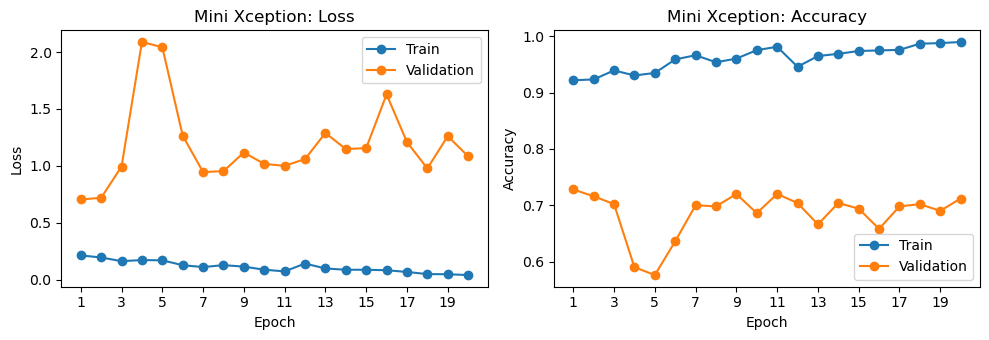

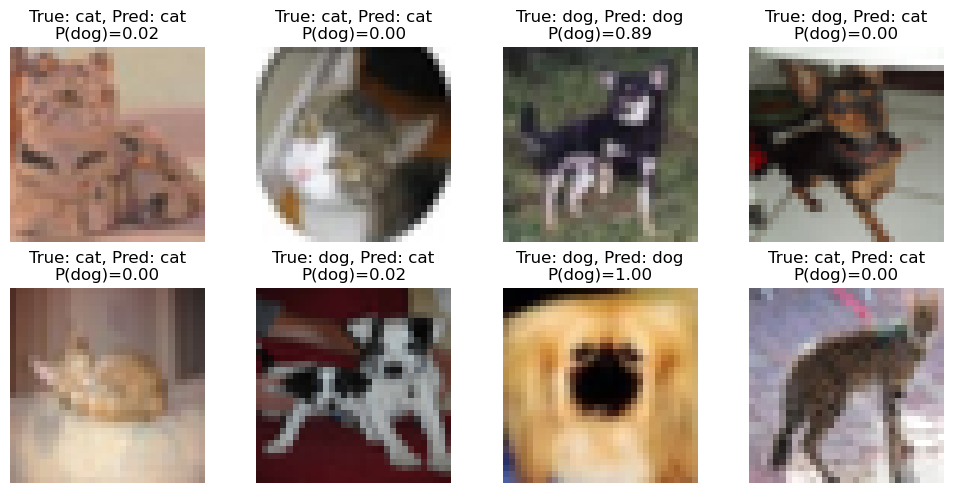

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
epochs = range(1, len(mini_history['loss']) + 1)

axes[0].plot(epochs, mini_history['loss'], marker='o', label='Train')
axes[0].plot(epochs, mini_history['val_loss'], marker='o', label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Loss', title='Mini Xception: Loss')
axes[0].set_xticks(range(1, 21, 2))
axes[0].legend()

axes[1].plot(epochs, mini_history['accuracy'], marker='o', label='Train')
axes[1].plot(epochs, mini_history['val_accuracy'], marker='o', label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Mini Xception: Accuracy')
axes[1].set_xticks(range(1, 21, 2))
axes[1].legend()

plt.tight_layout()

mini_x_examples = mini_x_val[:8].to(device)
mini_xception.eval()
with torch.no_grad():
    mini_dog_scores = torch.sigmoid(mini_xception(mini_x_examples)).cpu().numpy()

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(catdog_x_val[i].astype('uint8'))
    true_label = 'dog' if catdog_y_val[i] == 1 else 'cat'
    pred_label = 'dog' if mini_dog_scores[i] >= 0.5 else 'cat'
    ax.set_title(f'True: {true_label}, Pred: {pred_label}\nP(dog)={mini_dog_scores[i]:.2f}')
    ax.axis('off')
plt.tight_layout()


**해석·판단:** 모델이 구현되었다는 사실과 좋은 분류 성능을 얻었다는 사실은 다르다. 손실과 검증 정확도, 잘못 분류된 이미지를 함께 살펴보자. 채널 분리 합성곱이 파라미터 수를 줄인다고 해서 정확도가 자동으로 높아지는 것은 아니다.

**확인 질문:** 같은 이미지 분류 문제에서 사전훈련된 Xception과 직접 구현한 Mini Xception의 성능을 비교할 때, 모델 크기뿐 아니라 **사전훈련 여부, 훈련 에포크 수, 입력 처리, 검증 데이터** 중 무엇을 확인해야 할까?

## 실습 정리

- **CNN:** 이미지의 공간 구조를 보존하여 국소 필터를 여러 위치에 적용한다.
- **합성곱:** 필터 가중치를 학습하고 출력 특성맵을 만든다.
- **풀링:** 공간 크기를 줄이지만 학습할 파라미터는 없다.
- **데이터 증식:** 훈련 이미지를 다양하게 변형하되 라벨의 의미를 유지한다.
- **전이 학습:** 사전훈련 기저를 재활용한다. 미세 조정은 일부 층을 작은 학습률로 추가 훈련한다.
- **컴퓨터 비전:** 분류·탐지·분할은 예측해야 할 타깃의 형태부터 다르다.
- **CNN 아키텍처:** 잔차 연결, 배치 정규화, 채널 분리 합성곱에는 각각 다른 설계 목적이 있다. Mini Xception에서는 세 기법을 결합하여 이미지 분류 모델로 직접 사용했다.

## 확인 문제

1. MNIST CNN의 입력을 `(28, 28, 1)`로 사용하는 이유는 무엇인가?
2. 합성곱 필터 수를 32에서 64로 늘리면 출력의 어떤 차원이 달라지는가?
3. 맥스 풀링과 합성곱의 파라미터 학습 여부는 어떻게 다른가?
4. Keras의 `Conv2D`와 PyTorch의 `Conv2d` 입력 텐서 순서 차이는 무엇인가?
5. CIFAR-10 고양이·개 분류에서 데이터 증식 결과를 테스트 데이터에 적용하지 않는 이유는 무엇인가?
6. 사전훈련 기저에서 `trainable=False`를 사용하는 이유는 무엇인가?
7. 이미지 분류와 객체 탐지는 타깃의 형태가 어떻게 다른가?
8. 객체 탐지에서 신뢰도 임곗값을 높이면 어떤 변화가 생기는가?

<details><summary><strong>해설 보기</strong></summary>

1. 높이·너비 및 흑백 채널 정보를 보존하기 위해서다.
2. 출력 채널 수(마지막 축 또는 PyTorch에서는 두 번째 축)가 달라진다.
3. 합성곱의 필터는 학습하지만, 풀링은 정해진 규칙으로 값을 선택한다.
4. Keras: NHWC, PyTorch: NCHW다.
5. 평가에서는 훈련 때 사용한 무작위 변환이 아닌 증식하지 않은 검증·테스트 데이터를 사용하여 일반화 성능을 확인하기 위해서다.
6. 사전훈련된 가중치를 유지한 상태에서 새 분류 출력층을 훈련하기 위해서다.
7. 분류는 이미지당 클래스 하나를 예측하고, 객체 탐지는 각 객체의 클래스와 위치를 함께 예측한다.
8. 더 확실한 예측만 남고 탐지 수는 줄어드는 경향이 있다.

</details>